# 2. Load and inspect a dataset

A query returns catalog rows. The sections below turn one row into a `SpatialData` object that you can analyse. It
starts with what you can learn about a dataset before you download it, because stores range from 2 MB to almost
100 GB, and a full download is often not what you need.

You will learn how to:

- read the attributes of a `Dataset` and list its elements without downloading anything
- check the size of a store and choose what to fetch
- load a whole store, only some elements, or a copy in a folder of your choice
- find and manage the local cache
- look at the tables, shapes and images of the loaded object
- open the dataset on the website and in Vitessce, and know why some viewer links are hidden

The datasets here are small (under 10 MB each for what is downloaded), so the tutorial runs in a minute or two.
To run the plotting cells, install the client with the `viz` extra, as shown in {doc}`00_overview`.

In [1]:
import os
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import platformdirs
import spatialdata_plot  # noqa: F401  (adds the .pl accessor to SpatialData)
from spatialdata import get_extent

import sddb
from sddb.catalog import SITE_URL

cat = sddb.Catalog(version="2026-10-28")
work = Path(tempfile.mkdtemp())  # the files this tutorial writes go here

## A `Dataset` and its attributes

`Catalog.dataset` returns one catalog row as a `Dataset`. Each column of the catalog is an attribute, and a
missing value reads as `None`. The dataset below is a Visium section of a human pancreatic tumour, deposited in
GEO.

In [2]:
ds = cat.dataset("qEP9pd4LlyKeufe20000")
ds

<Dataset qEP9pd4LlyKeufe20000 technology=Visium organism=human>

In [3]:
{
    column: getattr(ds, column)
    for column in ["technology", "organism", "tissue", "condition", "n_obs", "n_features", "size_bytes", "license", "doi", "default_table"]
}

{'technology': 'Visium',
 'organism': 'human',
 'tissue': 'pancreas',
 'condition': 'PanIN and chronic pancreatitis in association with pancreatic ductal adenocarcinoma (PDAC)',
 'n_obs': np.int64(1142),
 'n_features': np.int64(17943),
 'size_bytes': np.int64(2577782),
 'license': 'ncbi-geo-policy',
 'doi': '10.1172/jci.insight.191595',
 'default_table': 'table'}

`condition` and `doi` come from the study, and `default_table` names the table that holds the main count matrix.
A cohort is a sequence of `Dataset` objects, so `for ds in cohort` and `cohort[0]` give the same kind of object.

`Catalog.dataset` also accepts the first 16 characters of the uid (the stem) and the `canonical_key`.
{doc}`03_cohorts_and_manifests` explains when to use which.

## Before you download

Store sizes vary by more than four orders of magnitude. `size_bytes` is the size of the whole store, and most of
it is usually images:

In [4]:
sizes = cat.to_df()["size_bytes"]
print(f"median {sizes.median() / 1e6:.0f} MB, largest {sizes.max() / 1e9:.0f} GB, {int((sizes > 1e9).sum())} stores above 1 GB")
print(f"this dataset: {ds.size_bytes / 1e6:.1f} MB")

median 63 MB, largest 96 GB, 1172 stores above 1 GB
this dataset: 2.6 MB


Two things tell you what is inside a store without downloading it. `elements()` reads the store's metadata and
returns every element with its shape and data type. The `sdata_repr` column holds the text that `print(sdata)`
gives for the loaded store.

In [5]:
for name, info in ds.elements().items():
    print(f"{name:42s} {info['shape']} {info['dtype']}")

images/GSM8915497_PDAC04_hires_image       (3, 1215, 2000) uint8
images/GSM8915497_PDAC04_lowres_image      (3, 365, 600) uint8
shapes/GSM8915497_PDAC04                   None None
tables/table                               (1142, 17943) float32


In [6]:
print(ds.sdata_repr)

SpatialData object
├── Images
│     ├── 'GSM8915497_PDAC04_hires_image': DataArray[cyx] (3, 1215, 2000)
│     └── 'GSM8915497_PDAC04_lowres_image': DataArray[cyx] (3, 365, 600)
├── Shapes
│     └── 'GSM8915497_PDAC04': GeoDataFrame shape: (1142, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (1142, 17943)
with coordinate systems:
    ▸ 'GSM8915497_PDAC04', with elements:
        GSM8915497_PDAC04_hires_image (Images), GSM8915497_PDAC04_lowres_image (Images), GSM8915497_PDAC04 (Shapes)
    ▸ 'GSM8915497_PDAC04_downscaled_hires', with elements:
        GSM8915497_PDAC04_hires_image (Images), GSM8915497_PDAC04 (Shapes)
    ▸ 'GSM8915497_PDAC04_downscaled_lowres', with elements:
        GSM8915497_PDAC04_lowres_image (Images), GSM8915497_PDAC04 (Shapes)


The store has two H&E images (a 2000-pixel "hires" and a 600-pixel "lowres" version, as Space Ranger writes
them), one shapes element with a circle per spot, and one table with 1142 spots and 17943 genes.

## Load the whole store

`to_sdata()` copies the store into the local cache and opens it with `spatialdata.read_zarr`. A download shows a
progress bar. A later call finds the copy and opens it without downloading, so if you ran the overview, the
dataset is already in the cache and no progress bar appears.

In [7]:
sdata = ds.to_sdata()
sdata

SpatialData object, with associated Zarr store: /tmp/sddb-docs-cache/stores/qEP9pd4LlyKeufe20000.zarr
├── Images
│     ├── 'GSM8915497_PDAC04_hires_image': DataArray[cyx] (3, 1215, 2000)
│     └── 'GSM8915497_PDAC04_lowres_image': DataArray[cyx] (3, 365, 600)
├── Shapes
│     └── 'GSM8915497_PDAC04': GeoDataFrame shape: (1142, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (1142, 17943)
with coordinate systems:
    ▸ 'GSM8915497_PDAC04', with elements:
        GSM8915497_PDAC04_hires_image (Images), GSM8915497_PDAC04_lowres_image (Images), GSM8915497_PDAC04 (Shapes)
    ▸ 'GSM8915497_PDAC04_downscaled_hires', with elements:
        GSM8915497_PDAC04_hires_image (Images), GSM8915497_PDAC04 (Shapes)
    ▸ 'GSM8915497_PDAC04_downscaled_lowres', with elements:
        GSM8915497_PDAC04_lowres_image (Images), GSM8915497_PDAC04 (Shapes)

## A first look at the data

The table is an `AnnData` object. `X` holds the counts, `obs` has one row per spot and `var` one row per gene.
In the pancreas table the gene symbols are the `var_names` and the Ensembl ids are in `var["gene_ids"]`. Other sources
store them the other way round, and the difference shows when you combine datasets ({doc}`03_cohorts_and_manifests`).

In [8]:
table = sdata.tables["table"]
table

AnnData object with n_obs × n_vars = 1142 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'spot_id', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs', 'spatial'
    obsm: 'spatial'
    layers: 'csc_counts'

In [9]:
table.var.head(3)

,gene_ids,feature_types,genome
SAMD11,ENSG00000187634,Gene Expression,unknown
NOC2L,ENSG00000188976,Gene Expression,unknown
KLHL17,ENSG00000187961,Gene Expression,unknown


The table annotates the shapes element. `spatialdata_attrs` names the shapes element (`region`) and the `obs`
column that matches each row to a shape (`instance_key`):

In [10]:
table.uns["spatialdata_attrs"]

{'region': 'GSM8915497_PDAC04',
 'instance_key': 'spot_id',
 'region_key': 'region'}

In [11]:
sdata.shapes["GSM8915497_PDAC04"].head(3)

,geometry,radius
spot_id,,
0,POINT (1738 1522),12.477101
1,POINT (2890 1457),12.477101
2,POINT (2659 1790),12.477101


Each spot is a circle with a centre and a radius. The images and shapes are placed in a common space through
coordinate systems. Space Ranger stores the image at two
resolutions, and the coordinate system `..._downscaled_hires` puts the spots on top of the hires image.

The figure shows the H&E image next to two genes: `COL1A1`, which marks the fibrous stroma around a pancreatic
tumour, and `CELA3A`, an enzyme of acinar cells, the normal exocrine pancreas. The colours show log(1 + counts):
`transfunc=np.log1p` transforms the values only for the plot, so the counts in `table` stay as they are.
`get_extent` gives the bounding box of the spots, and `crop_coord` crops the empty slide around the tissue.

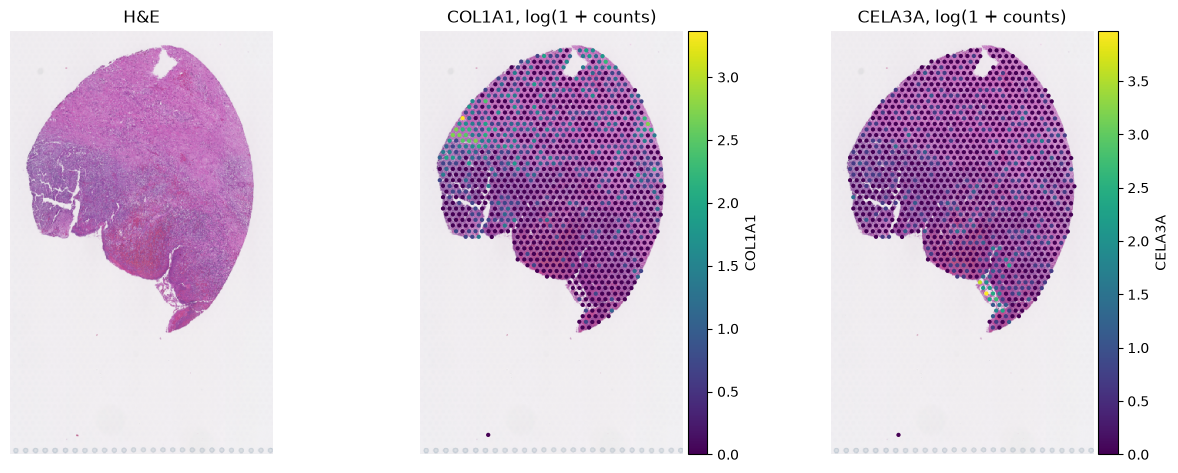

In [12]:
image = "GSM8915497_PDAC04_hires_image"
spots = "GSM8915497_PDAC04"
coordinates = "GSM8915497_PDAC04_downscaled_hires"

extent = get_extent(sdata, coordinate_system=coordinates, elements=[spots])
crop = (extent["x"][0] - 40, extent["x"][1] + 40, extent["y"][0] - 40, extent["y"][1] + 40)  # 40 pixels of margin

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
(
    sdata
    .pl.render_images(image)
    .pl.show(
        coordinate_systems=coordinates,
        crop_coord=crop,
        ax=axes[0],
        frameon=False,
        title="H&E",
    )
)
(
    sdata
    .pl.render_images(image)
    .pl.render_shapes(spots, color=["COL1A1", "CELA3A"], table_name="table", transfunc=np.log1p)
    .pl.show(
        coordinate_systems=coordinates,
        crop_coord=crop,
        ax=list(axes[1:]),
        frameon=False,
        title=["COL1A1, log(1 + counts)", "CELA3A, log(1 + counts)"],
    )
)

The section has few counts per spot, so most spots are dark in both panels. `COL1A1` is highest along the left
edge of the section and `CELA3A` at the lower tip, so the two genes mark different parts of the tissue.

## Load only some elements

Most of a large store is images. If you only need the counts, `elements=` copies only the elements you name, as
`"kind/name"` paths from `elements()`. The client also copies the shapes or labels that a kept table annotates,
so the table keeps its link to space.

The next dataset is a Visium section from HEST. Its store is 63 MB, almost all of it a full-resolution image of
8192 by 7953 pixels. Its `default_table` is `None`, which happens for some sources, so read the table name from
`elements()`.

In [13]:
hest = cat.dataset("USx288NLowiqKbV30000")
print(f"{hest.size_bytes / 1e6:.0f} MB, default_table={hest.default_table}")
for name, info in hest.elements().items():
    print(f"{name:30s} {info['shape']}")

63 MB, default_table=None
images/NCBI466_full_image      (3, 8192, 7953)
shapes/NCBI466_spots           None
tables/table                   (691, 19850)


In [14]:
counts_only = hest.to_sdata(elements=["tables/table"])
counts_only

SpatialData object, with associated Zarr store: /tmp/sddb-docs-cache/elements/USx288NLowiqKbV30000/USx288NLowiqKbV3__abb7104aa4a2.zarr
├── Shapes
│     └── 'NCBI466_spots': GeoDataFrame shape: (691, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (691, 19850)
with coordinate systems:
    ▸ 'global', with elements:
        NCBI466_spots (Shapes)

In [15]:
def size_on_disk(path: Path) -> float:
    """Total size of the files under ``path``, in MB."""
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 1e6


print(f"copied {size_on_disk(counts_only.path):.1f} MB of {hest.size_bytes / 1e6:.0f} MB")

copied 4.3 MB of 63 MB


The copy holds the table and the spot shapes it annotates, and no image. The warning about variable names comes
from the HEST table, where two genes appear twice. {doc}`03_cohorts_and_manifests` shows how `to_anndata` handles
repeated gene names.

## Keep a copy in your own folder

Without `dest`, stores go to the cache. With `dest`, the store goes to `dest/<uid>.zarr`, and `dest/manifest.json`
records what was copied, from where, and whether the copy is whole or partial. Use `dest` for data that a project
depends on, so it does not live in a cache you might clear.

In [16]:
project = work / "data"
partial = hest.to_sdata(elements=["tables/table"], dest=project)
print(sorted(p.name for p in project.iterdir()))
print((project / "manifest.json").read_text())

['USx288NLowiqKbV30000.zarr', 'manifest.json']
{
  "generated_at": "2026-10-31T23:38:46.025989+00:00",
  "catalog_version": null,
  "entries": [
    {
      "uid": "USx288NLowiqKbV30000",
      "zarr_url": "s3://scverse-spatial-eu-central-1/.lamindb/USx288NLowiqKbV3.zarr",
      "dest": "/tmp/sddb-docs-tmp/tmp1hfpqka_/data/USx288NLowiqKbV30000.zarr",
      "size_bytes": 4335866,
      "status": "partial",
      "sha256": "3ec0e4f397cc89ec352575cf5ab2261b65bc375fcb890f4644f535219c1ed256",
      "error": null,
      "elements": [
        "tables/table"
      ]
    }
  ]
}


The entry has `status: "partial"` and lists the elements. A later `download()` of a cohort with the HEST dataset into
the same folder fetches the whole store and replaces the partial copy. {doc}`03_cohorts_and_manifests` covers
`download()` and its manifest.

## The cache

The cache is a folder called `sddb` in your platform's user cache directory, or the folder in the environment
variable `SDDB_CACHE_DIR`. Set the variable before you import the client to put the cache on a larger disk.

In [17]:
cache = Path(os.environ.get("SDDB_CACHE_DIR") or platformdirs.user_cache_dir("sddb"))
for folder in sorted(p for p in cache.iterdir() if p.is_dir()):
    print(f"{folder.name:10s} {size_on_disk(folder):8.1f} MB")

catalog       956.6 MB
elements        4.3 MB
stores         18.0 MB


- `catalog` holds the catalog files and `citations.bib`, one per release you opened.
- `stores` holds whole stores from `to_sdata()`, one `<uid>.zarr` per dataset.
- `elements` holds the partial copies from `to_sdata(elements=...)`.

The cache is keyed by the full uid. When a dataset gets a new version, its uid changes and the client downloads
the new store rather than reusing the old copy. Nothing is ever deleted for you, so remove the folder by hand when
it gets large. The next call downloads what it needs again.

## The website and Vitessce

Every dataset has a page on the website, at the address built from its `slug`. `card_url` links the dataset in
Lamin, and `dataset_url` links the source (here the GEO series).

In [18]:
print(f"{SITE_URL}/datasets/{ds.slug}/")
print(ds.card_url)
print(ds.dataset_url)

https://spatialdata-db-web.pages.dev/datasets/visium-spatial-gene-expression-pancreas-qep9pd4llykeufe20000/
https://lamin.ai/scverse/spatialdata-db/artifact/qEP9pd4LlyKeufe20000
https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE294669


`viewer_url()` returns a link that opens the dataset in Vitessce, a viewer that runs in the browser. The link
contains the whole viewer configuration, so it is long. `view()` opens it in your browser, and
`view_interactive()` shows it inside a notebook. Both need the `viz` extra.

In [19]:
url = ds.viewer_url()
print(url[:80] + "...", f"({len(url)} characters)")

https://vitessce.io#?edit=false&url=data:,%257B%2522version%2522%253A%2520%25221... (8963 characters)


In the 2026-10-28 release, 333 of the 5937 viewer links load the store of another dataset, because of an error
in the catalog. The client checks every link against the dataset's own store, as the website does. For a link
that does not match, `viewer_url()` warns and returns `None`, and `view()` raises a `ValueError`. The viewer link
of a small Xenium kidney section, `NHyd5DFysygNrkdu0000`, is one of them:

In [20]:
kidney = cat.dataset("NHyd5DFysygNrkdu0000")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    print(kidney.viewer_url())
print(caught[0].message)

None
the viewer link for NHyd5DFysygNrkdu0000 loads another dataset's store; it is hidden until the catalog is fixed


Counting the hidden links over the whole catalog gives the 333. The warnings are switched off here, because there
would be one per hidden link.

In [21]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    hidden = [d.uid for d in cat.query() if d.vitessce_url and d.viewer_url() is None]
print(len(hidden), "viewer links hidden")

333 viewer links hidden


## Summary

- `Dataset` attributes, `elements()` and `sdata_repr` describe a dataset without a download. Check `size_bytes`
  first.
- `to_sdata()` caches the whole store, `elements=` copies only what you name, and `dest=` keeps a copy with a
  manifest in a folder of your choice.
- The cache lives in `SDDB_CACHE_DIR` or the user cache directory, keyed by full uid.
- `viewer_url()` returns `None` with a warning when a link would open another dataset.

Next: [3. Cohorts and manifests](03_cohorts_and_manifests.ipynb), which works with many datasets at once and
makes the selection reproducible.